# 05 Model comparison: BidLens against the engineer's estimate

**The question.** Which pricing method should BidLens use? And the estimator's real question: is a BidLens total for a whole contract closer to the winning bid than Caltrans' own engineer's estimate?

**What we did.**
1. **Chose the method before looking at the test** (decision D-046): every method was scored on 2023 bids, with only earlier bids as history. Kumo Tabular won (36.8% median miss, against 40.1% XGBoost, 41.2% LightGBM, 56.8% median), and no item family cleared the 5-point bar for an exception.
2. **Refreshed each quarter** (decision D-045): in real use BidLens always has the latest bids. So before pricing a quarter, each model sees every bid opened before that quarter (Kumo's table grows; XGBoost and LightGBM are refit). It never sees the bids it is pricing. This is what removes the drift found in notebook 04.
3. **Priced whole contracts** (decisions D-037, D-038): for each test contract, every line of the bid list is priced (top-100 items by the model, other items by earlier low bids for the same item) and added up, then compared with the engineer's estimate and the actual low bid. The headline uses the **178 test contracts** where at least 90% of lines have price history.
4. **Added a low / likely / high range** to every price (decision D-047), recalibrated each quarter on past results so it holds the low bid about 8 times in 10.

**What we found.**
- Refreshed, Kumo misses single items by **38.2%** (from 40.2% frozen), and the drift is gone: the median lean moves from 13% too high to 9% too low.
- **Headline: the BidLens total landed closer to the low bid than the engineer's estimate on 57.9% of the 178 test contracts.** Typical miss **18.4%** against **21.2%** for the estimate; within 15% on **43.3%** of contracts against 35.4%. The BidLens total is centred on the low bid (median **+0.8%**); the engineer's estimate sits **19.9%** above it.
- **Where it loses:** on 42% of contracts the engineer's estimate was closer. The estimate is a cost build-up, not a prediction of the low bid, and in 2024 to 2026 low bids in these districts came in well under it, which helps a method built from earlier low bids. Kumo is beaten in 7 of 18 item families on single items (shown below).
- The range held the actual low bid on **79.0%** of test prices (target 80%). Ranges are wide (typically 4x from low to high for unit-priced items, 13x for lump sums), an honest reflection of how noisy single low bids are.

The full reports: [`outputs/13_model_comparison/`](../outputs/13_model_comparison/README.md) and [`outputs/14_price_ranges/`](../outputs/14_price_ranges/README.md).

## Setup

This loads the project's own code (`src/bidlens/analysis/stages.py`), which reads the results each stage already saved in `outputs/` (decision D-070). Nothing is recomputed here, so the notebook runs in seconds on a fresh copy of the repository, with no database and no model downloads.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root

import matplotlib.pyplot as plt
import pandas as pd

from bidlens.analysis import stages as s

pd.set_option("display.max_colwidth", 140)
plt.rcParams["figure.max_open_warning"] = 0

## The choice, made on 2023 bids

Median miss on 2023 bids, with only earlier bids as history. The test years (2024 to 2026) played no part in the choice, so the results below are an honest check of it.

In [2]:
s.validation_choice()

,Method,Median miss on 2023 bids
0,Historical median,56.8%
1,XGBoost,40.1%
2,LightGBM,41.2%
3,Kumo Tabular,36.8%


## Frozen models against models refreshed each quarter

Refreshing improves every model and pulls its lean (the median over or under the low bid) back toward zero. The chart shows Kumo year by year: frozen, it drifts from 7% to 24% too high; refreshed, it sits a little low in every year.

In [3]:
s.refreshed_vs_frozen()

,Method,How it runs,Median miss,Within 15%,Median over (+) / under (-)
0,XGBoost,Frozen at the end of 2023,46.1%,18.0%,+27.9%
1,XGBoost,Refreshed each quarter,40.1%,20.9%,+2.0%
2,LightGBM,Frozen at the end of 2023,43.4%,19.4%,+20.6%
3,LightGBM,Refreshed each quarter,38.9%,20.9%,+0.5%
4,Kumo Tabular,Frozen at the end of 2023,40.2%,20.5%,+13.4%
5,Kumo Tabular,Refreshed each quarter,38.2%,20.8%,-9.3%


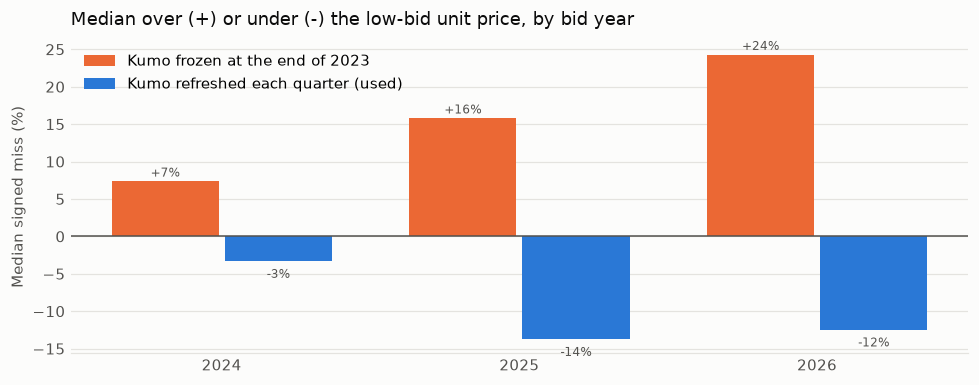

In [4]:
fig = s.chart_drift(s.kumo_drift_frozen_vs_refreshed())
s.save(fig, "drift_frozen_vs_refreshed", s.S13)
plt.show()

## Single items by family, refreshed

The production method (Kumo, refreshed) against the alternatives. Kumo is best on traffic control, asphalt, water pollution control, fencing and guardrail, structural concrete, electrical, bridge rehabilitation, drainage, concrete pavement and piling. LightGBM wins general and overhead, striping, earthwork, minor concrete and steel structures; XGBoost wins landscape and base. None of these gaps cleared the pre-set bar for a family exception on 2023 bids.

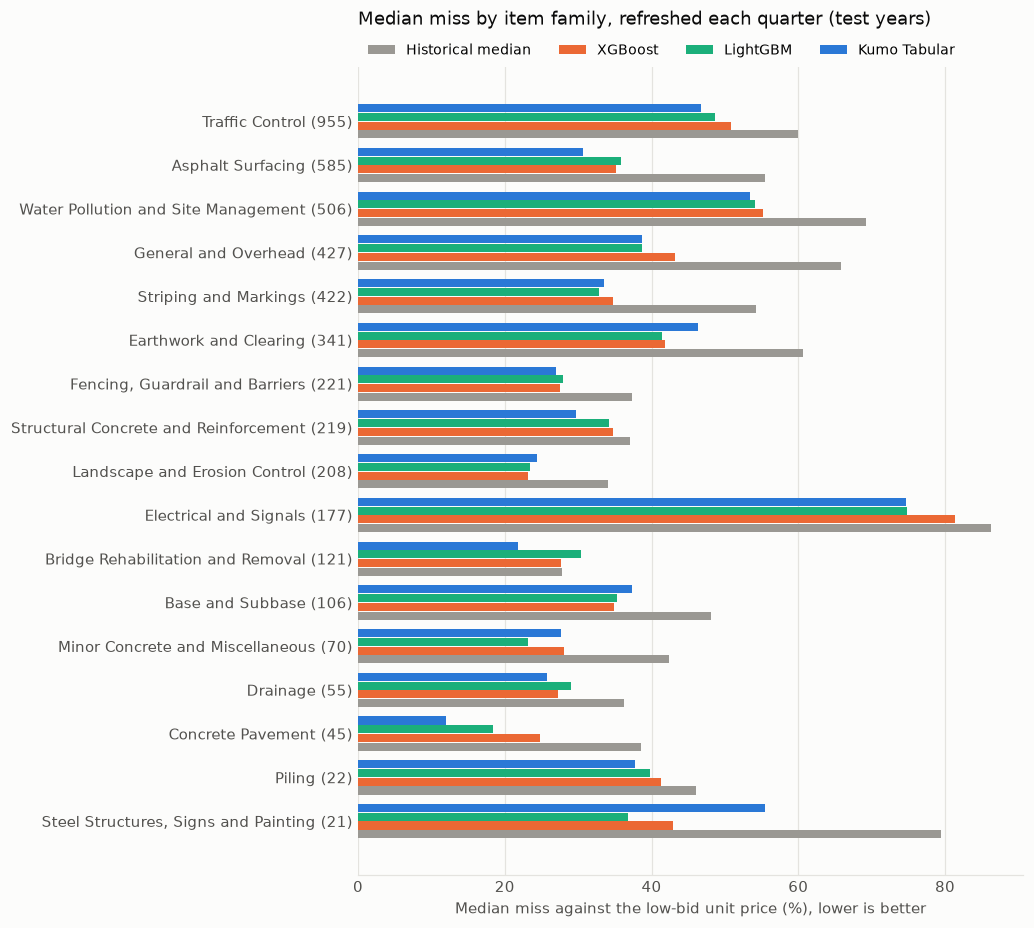

In [5]:
fam = pd.read_csv(s.S13 / "test_by_family.csv")
fig = s.chart_family_mdape(
    fam, list(s.METHODS), "Median miss by item family, refreshed each quarter (test years)"
)
s.save(fig, "mdape_by_family_refreshed", s.S13)
plt.show()

## The headline: whole contracts

Each dot is one test contract: how far the total landed above (+) or below (−) the actual low bid. The black tick is the median. The BidLens totals are centred on zero; the engineer's estimates sit about 20% high. A few contracts miss by a lot either way (dots past +100% are clipped at +150%).

In [6]:
s.headline()

,Total built with,Closer than the EE,Typical miss,Median over (+) / under (-),Within 15%
0,Historical median,31.5%,43.0%,+38.2%,20.2%
1,XGBoost,54.5%,21.8%,+10.9%,34.3%
2,LightGBM,55.6%,22.0%,+7.6%,34.8%
3,"Kumo Tabular (BidLens, chosen)",57.9%,18.4%,+0.8%,43.3%
4,Engineer's estimate,,21.2%,+19.9%,35.4%


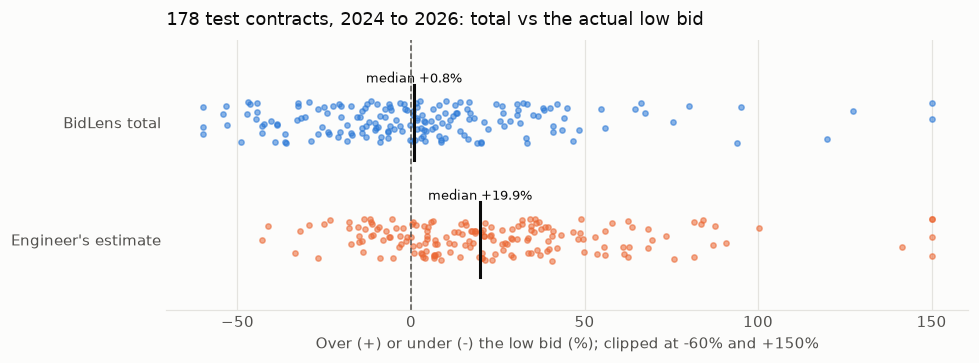

In [7]:
totals = s.contract_totals()
fig = s.chart_contract_errors(totals)
s.save(fig, "contract_totals_vs_low_bid", s.S13)
plt.show()

## Price ranges

Kumo gives a spread of possible prices. Each quarter, BidLens checks how often its 10th-to-90th percentile range held the low bid on every earlier priced item and adjusts the range so it would have held 80%, separately for lump sums and unit-priced items. On the test years it held 79.0%. Each dot below is one item family: dots inside the grey band (75 to 85%) are well calibrated.

In [8]:
s.range_summary()

,Range,Held the low bid,Below low,Above high,Typical width (high / low)
0,Kumo's own 10th to 90th percentile range,82.7%,6.4%,10.9%,6.0x
1,BidLens range (recalibrated each quarter),79.0%,7.6%,13.4%,5.3x


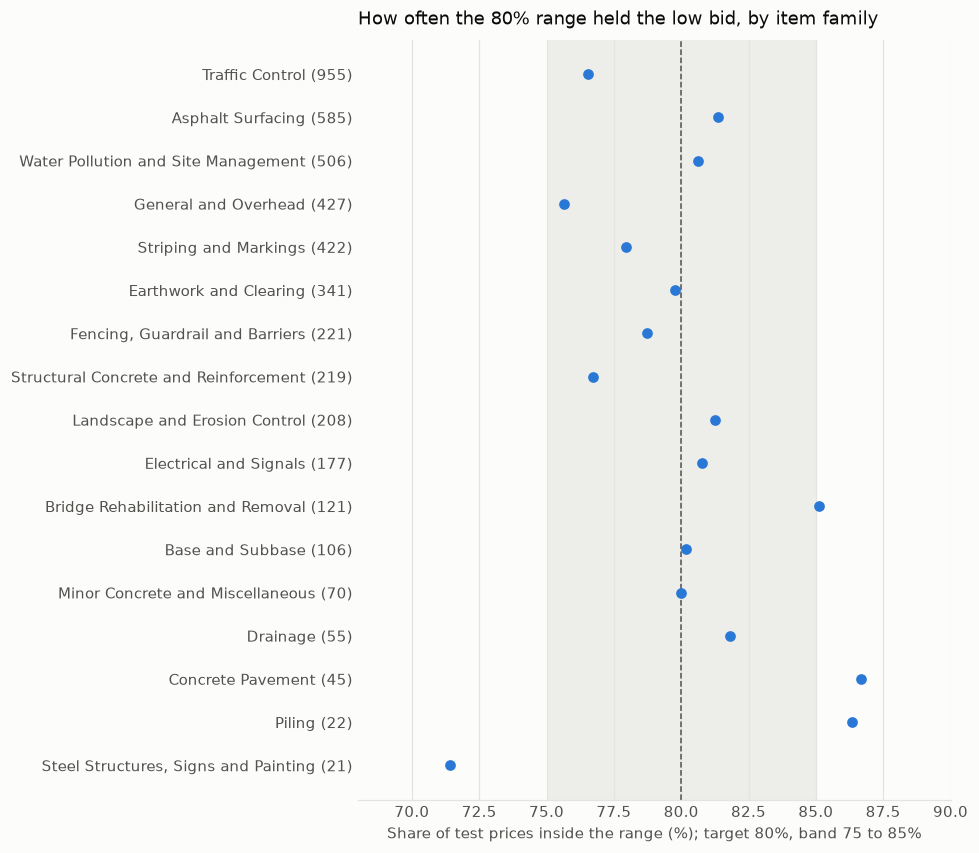

In [9]:
fig = s.chart_range_coverage(s.range_coverage())
s.save(fig, "range_coverage_by_family", s.S14)
plt.show()

Every price also comes with its **10 most similar earlier low bids** for the same item (decision D-048): closest in quantity first, then recent, same district and similar contract size, each linked to its Caltrans source page. 99.2% of test prices have a full 10, and the actual low bid falls inside their span on 81.4% of items. Examples are in [`outputs/14_price_ranges/README.md`](../outputs/14_price_ranges/README.md).

## Save and next

This adds the charts above to `outputs/13_model_comparison/` and `outputs/14_price_ranges/`. To recompute (about 12 minutes): `make pricing`.

**Next:** *06 Market context*: how many bidders, and where the low bid will land against the engineer's estimate.

In [10]:
s.note_in_readme(s.S13, "05_model_comparison.ipynb")
s.note_in_readme(s.S14, "05_model_comparison.ipynb")
sorted(p.name for d in (s.S13, s.S14) for p in d.glob("nb_*.png"))

['nb_contract_totals_vs_low_bid.png',
 'nb_drift_frozen_vs_refreshed.png',
 'nb_mdape_by_family_refreshed.png',
 'nb_range_coverage_by_family.png']